# Задание 2. Autograd для скаляров

Нужно написать класс `Node` - число, которое помнит, из каких чисел и какой операцией оно получено, и умеет обратным проходом посчитать производные результата по всем промежуточным значениям. Обязательные операции - сложение, умножение и ReLU. Кроме них добавил вычитание, деление, степень, `exp`, `log`, `tanh` и `sigmoid`, чтобы из `Node` можно было собрать что-то полезное (в конце обучаю на нем маленькую сеть).

Внутри класса torch не используется вообще: только арифметика Python и `math`. torch.autograd дальше нужен только как эталон, с которым сравниваю градиенты.

In [1]:
import gc
import io
import math
import random
import shutil
import sys
import time
import unittest

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as IPyImage, display
from sklearn.datasets import make_moons

try:
    import graphviz  # нужен только для картинки графа
except ImportError:
    graphviz = None

from utils import set_seed

## Немного теории

Любое выражение раскладывается на элементарные операции, и получается вычислительный граф: вершины - значения, у каждой вершины есть операция и аргументы, из которых она получена. Для примера из условия $d = a + b \cdot c,\ e = \mathrm{ReLU}(d)$ граф такой: `b, c -> (*) -> bc`, `a, bc -> (+) -> d`, `d -> (relu) -> e`.

Производные по графу считаются по цепному правилу. Пусть $L$ - итоговое значение (выход графа), а вершина $x$ используется как аргумент в вершинах $y_1, \dots, y_k$. Тогда

$$\frac{\partial L}{\partial x} = \sum_{i=1}^{k} \frac{\partial L}{\partial y_i}\,\frac{\partial y_i}{\partial x},$$

где $\partial y_i / \partial x$ - локальная производная операции, она известна заранее:

| операция | $\partial z / \partial x$ | $\partial z / \partial y$ |
|---|---|---|
| $z = x + y$ | $1$ | $1$ |
| $z = x \cdot y$ | $y$ | $x$ |
| $z = \mathrm{ReLU}(x) = \max(0, x)$ | $[x > 0]$ | - |

В нуле производную ReLU беру равной 0, как в torch. Сумма в формуле - причина, почему градиенты надо накапливать через `+=`, а не присваивать: если значение используется несколько раз (`a * a`, `a + a`, общие подвыражения), вклады складываются.

Идти по графу можно и от входов к выходу (forward mode), но тогда за один проход получаются производные всех вершин по одному входу, и для $n$ параметров нужно $n$ проходов. В нейросетях выход один (лосс), а параметров много, поэтому идут от выхода к входам (reverse mode): за один обратный проход получаем $\partial L / \partial v$ сразу для всех вершин $v$, и стоит это примерно как один прямой проход. Это и есть backpropagation.

Остается порядок обхода. Вершина $v$ в своем `_backward` раздает градиент аргументам, значит к этому моменту $\partial L / \partial v$ должен быть посчитан полностью, т.е. все вершины, которые используют $v$, уже обработаны. Поэтому вершины обходятся в обратном топологическом порядке, от выхода к листьям. Сортировку делаю обходом в глубину, но не рекурсивным, а на явном стеке: рекурсивный падает с `RecursionError`, как только глубина графа больше лимита рекурсии Python (1000 в обычном Python, 3000 в Jupyter), а, например, сумма из 10000 слагаемых - цепочка как раз такой глубины.

## Реализация

Каждая операция создает новый `Node`, запоминает аргументы (`_prev`) и название операции (`_op`) и кладет в `_backward` замыкание, которое умножает градиент результата на локальную производную и добавляет к `.grad` аргументов. Несколько деталей:

- числа Python заворачиваются в `Node`, поэтому работают `2 * a`, `a + 1`, `1 - a`, `1 / a` (для чисел слева нужны `__radd__`, `__rmul__` и т.д.);
- у вычитания и деления своя локальная производная ($1$ и $-1$; $1/y$ и $-x/y^2$), как и у унарного минуса, `pow`, `exp`, `log`, `tanh`, `sigmoid`. Функции одного аргумента делаются через общий метод `_unary`, которому передается значение и производная;
- кроме `_prev` из шаблона (это `set`) храню `_args` - те же аргументы в порядке появления. Обход графа идет по `_args`: порядок обхода `set` из объектов зависит от их адресов в памяти, и тогда от запуска к запуску менялся бы порядок сложения вкладов в градиенты, а с ним последние знаки результата;
- `backward()` обнуляет градиенты промежуточных вершин и считает их заново, а у листьев градиенты накапливаются между вызовами, как у параметров в torch. Поэтому перед каждым шагом обучения градиенты надо обнулять (`zero_grad()`);
- если положить в `data` 0-мерный тензор torch (без `requires_grad`), то `+`, `*` и `relu` тоже работают и результат остается тензором: им нужны только арифметика и сравнение.

In [2]:
class Node:
    """Скалярное значение, которое помнит, как было получено, и умеет считать градиенты."""

    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self.grad = 0
        self._backward = lambda: None
        self._prev = set(_children)
        self._args = tuple(dict.fromkeys(_children))  # те же аргументы, но в фиксированном порядке
        self._op = _op

    def __repr__(self):
        return f"Node(data={self.data}, grad={self.grad})"

    @staticmethod
    def _as_node(value):
        return value if isinstance(value, Node) else Node(value)

    # обязательные операции

    def __add__(self, other):
        other = Node._as_node(other)
        out = Node(self.data + other.data, (self, other), '+')

        def _backward():
            # d(x + y)/dx = d(x + y)/dy = 1
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = Node._as_node(other)
        out = Node(self.data * other.data, (self, other), '*')

        def _backward():
            # d(xy)/dx = y, d(xy)/dy = x
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def relu(self):
        # data - data: ноль того же типа, что data (int, float, 0-мерный тензор)
        out = Node(self.data if self.data > 0 else self.data - self.data, (self,), 'relu')

        def _backward():
            # производная 1 при x > 0, иначе 0 (в нуле тоже 0, как в torch)
            self.grad += (self.data > 0) * out.grad
        out._backward = _backward
        return out

    # числа слева: 2 * a, 3 + a

    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    # остальные операции

    def __sub__(self, other):
        other = Node._as_node(other)
        out = Node(self.data - other.data, (self, other), '-')

        def _backward():
            # d(x - y)/dx = 1, d(x - y)/dy = -1
            self.grad += out.grad
            other.grad -= out.grad
        out._backward = _backward
        return out

    def __rsub__(self, other):
        return Node._as_node(other) - self

    def __truediv__(self, other):
        other = Node._as_node(other)
        out = Node(self.data / other.data, (self, other), '/')

        def _backward():
            # d(x/y)/dx = 1/y, d(x/y)/dy = -x/y^2
            self.grad += out.grad / other.data
            other.grad -= out.grad * self.data / other.data ** 2
        out._backward = _backward
        return out

    def __rtruediv__(self, other):
        return Node._as_node(other) / self

    def _unary(self, value, local_grad, op):
        """Функция одного аргумента: value = f(x), local_grad = f'(x)."""
        out = Node(value, (self,), op)

        def _backward():
            self.grad += local_grad * out.grad
        out._backward = _backward
        return out

    def __neg__(self):
        return self._unary(-self.data, -1, 'neg')

    def __pow__(self, k):
        """Степень с числовым показателем (у отрицательного основания - только целым)."""
        if not isinstance(k, (int, float)):
            return NotImplemented
        if self.data < 0 and k != int(k):
            raise ValueError("дробная степень отрицательного числа")
        out = Node(self.data ** k, (self,), f'**{k}')

        def _backward():
            if k != 0:  # при k = 0 производная 0, а 0 ** -1 считать нельзя
                self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    # функции через math: log(x <= 0) или переполнение exp дают ошибку, как в самом math

    def exp(self):
        e = math.exp(self.data)
        return self._unary(e, e, 'exp')

    def log(self):
        return self._unary(math.log(self.data), 1 / self.data, 'log')

    def tanh(self):
        t = math.tanh(self.data)
        return self._unary(t, 1 - t * t, 'tanh')

    def sigmoid(self):
        x = self.data
        # две формулы, чтобы exp не переполнялся при больших |x|
        s = 1 / (1 + math.exp(-x)) if x >= 0 else math.exp(x) / (1 + math.exp(x))
        return self._unary(s, s * (1 - s), 'sigmoid')

    # обратный проход

    def _topo_order(self):
        """Вершины графа в топологическом порядке: аргументы раньше результатов.

        DFS на явном стеке: вершина попадает в список только после всех своих аргументов.
        """
        order, visited = [], set()
        stack = [(self, False)]
        while stack:
            node, children_done = stack.pop()
            if children_done:
                order.append(node)
            elif node not in visited:
                visited.add(node)
                stack.append((node, True))
                stack.extend((child, False) for child in node._args if child not in visited)
        return order

    def backward(self):
        """Считает d(self)/d(v) для всех вершин v графа.

        Градиенты листьев накапливаются между вызовами (как в torch),
        у промежуточных вершин они каждый раз считаются заново.
        """
        order = self._topo_order()
        for node in order:
            if node._args:
                node.grad = 0
        self.grad += 1
        for node in reversed(order):
            node._backward()

    def zero_grad(self):
        """Обнуляет градиенты всех вершин графа."""
        for node in self._topo_order():
            node.grad = 0

## Пример из условия

Запускаю ровно тот код, что в условии.

In [3]:
a = Node(2)
b = Node(-3)
c = Node(10)
d = a + b * c
e = d.relu()
e.backward()
print(a, b, c, d, e)

Node(data=2, grad=0) Node(data=-3, grad=0) Node(data=10, grad=0) Node(data=-28, grad=0) Node(data=0, grad=1)


Вывод отличается от того, что написано в условии (там `b.grad=10`, `c.grad=-3`, `d.grad=1`). Проверим тот же пример через torch.autograd, а заодно второй вариант с `c = -10`, где ReLU активен.

In [4]:
def node_assignment_example(c_value):
    a, b, c = Node(2), Node(-3), Node(c_value)
    d = a + b * c
    e = d.relu()
    e.backward()
    return a, b, c, d, e


def torch_assignment_example(c_value):
    # torch.autograd здесь только как эталон
    ta, tb, tc = (torch.tensor(float(v), requires_grad=True) for v in (2, -3, c_value))
    td = ta + tb * tc
    te = td.relu()
    td.retain_grad()
    te.retain_grad()
    te.backward()
    return ta, tb, tc, td, te


example_columns = {}
for example_c in (10, -10):
    example_nodes = node_assignment_example(example_c)
    example_tensors = torch_assignment_example(example_c)
    print(f"c = {example_c}:", *example_nodes)
    example_columns[(f"c = {example_c}", "data")] = [n.data for n in example_nodes]
    example_columns[(f"c = {example_c}", "grad Node")] = [n.grad for n in example_nodes]
    example_columns[(f"c = {example_c}", "grad torch")] = [
        t.grad.item() + 0.0 for t in example_tensors  # + 0.0 убирает -0.0
    ]

pd.DataFrame(example_columns, index=list("abcde"))

c = 10: Node(data=2, grad=0) Node(data=-3, grad=0) Node(data=10, grad=0) Node(data=-28, grad=0) Node(data=0, grad=1)
c = -10: Node(data=2, grad=1) Node(data=-3, grad=-10) Node(data=-10, grad=-3) Node(data=32, grad=1) Node(data=32, grad=1)


c = 10                      c = -10                     
    data grad Node grad torch    data grad Node grad torch
a      2         0        0.0       2         1        1.0
b     -3         0        0.0      -3       -10      -10.0
c     10         0        0.0     -10        -3       -3.0
d    -28         0        0.0      32         1        1.0
e      0         1        1.0      32         1        1.0

Градиенты `Node` совпадают с torch в обоих случаях. Посчитаем руками для `c = 10`: $d = 2 + (-3) \cdot 10 = -28 < 0$, значит $e = \mathrm{ReLU}(d) = 0$ и производная ReLU в этой точке равна нулю. По цепному правилу

$$\frac{\partial e}{\partial d} = [d > 0] = 0,\qquad
\frac{\partial e}{\partial a} = \frac{\partial e}{\partial d} \cdot 1 = 0,\qquad
\frac{\partial e}{\partial b} = \frac{\partial e}{\partial d} \cdot c = 0,\qquad
\frac{\partial e}{\partial c} = \frac{\partial e}{\partial d} \cdot b = 0,$$

ненулевой градиент только у самого выхода: $\partial e / \partial e = 1$. Так что верный ответ - нули у `a, b, c, d`.

В условии, судя по всему, опечатка: там градиент как будто прошел через ReLU ($\partial e/\partial d = 1$, отсюда `b.grad = c = 10` и `c.grad = b = -3`), но тогда и `a.grad` был бы равен 1, а не 0, так что вывод в условии противоречит сам себе. Кроме того, в шаблоне `__repr__` печатает `Element(...)` (видимо, осталось от старого имени класса), а в выводе примера - `Node(...)`, я печатаю `Node(...)`.

При `c = -10` получается $d = 2 + 30 = 32 > 0$, ReLU пропускает градиент, и выходит как раз то, что ожидалось: `a.grad = 1`, `b.grad = c = -10`, `c.grad = b = -3`, `d.grad = e.grad = 1`.

## Граф вычислений

Нарисую граф второго примера (`c = -10`) после `backward()`: в каждой вершине значение и градиент. Если graphviz не установлен, граф просто печатается текстом.

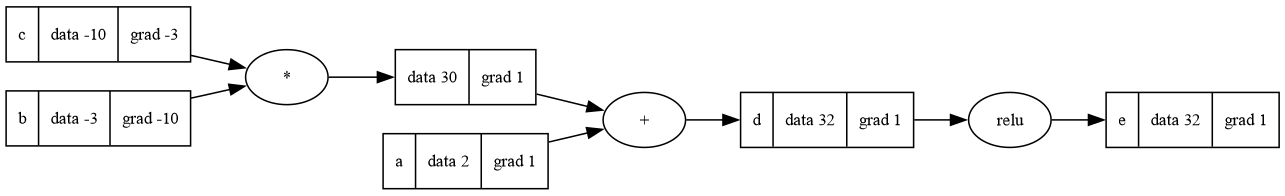

In [5]:
def node_graph_lines(root, names=None):
    """Текстовое описание графа: по строке на вершину, от листьев к выходу."""
    names = dict(names or {})
    lines, n_unnamed = [], 0
    for node in root._topo_order():
        if node not in names:
            n_unnamed += 1
            names[node] = f"t{n_unnamed}"
        args = [names[child] for child in node._args]
        if node._op in ("+", "-", "*", "/") and len(args) == 2:
            expr = f" {node._op} ".join(args)
        elif node._op:
            expr = f"{node._op}({', '.join(args)})"
        else:
            expr = "лист"
        lines.append(f"{names[node]:>3} = {expr:<10} data={node.data:g}, grad={node.grad:g}")
    return lines


def node_graph_dot(root, names=None):
    """Тот же граф в виде graphviz.Digraph: вершины-значения и отдельные вершины-операции."""
    names = dict(names or {})
    dot = graphviz.Digraph(graph_attr={"rankdir": "LR", "dpi": "110"}, node_attr={"fontsize": "11"})
    for node in root._topo_order():
        uid = str(id(node))
        name = names.get(node)
        label = (f"{name} | " if name else "") + f"data {node.data:g} | grad {node.grad:g}"
        dot.node(uid, label="{" + label + "}", shape="record")
        if node._op:
            dot.node(uid + "op", label=node._op, shape="ellipse")
            dot.edge(uid + "op", uid)
            for child in node._args:
                dot.edge(str(id(child)), uid + "op")
    return dot


a, b, c, d, e = node_assignment_example(-10)
graph_names = {a: "a", b: "b", c: "c", d: "d", e: "e"}
if graphviz is not None and shutil.which("dot"):
    display(IPyImage(node_graph_dot(e, graph_names).pipe(format="png")))
else:
    print("\n".join(node_graph_lines(e, graph_names)))
del a, b, c, d, e  # короткие имена дальше не нужны

Видно, как градиент идет справа налево: через `relu` проходит без изменений (вход положительный), на `+` копируется в оба аргумента, а на `*` аргументы "меняются местами": `b` получает значение `c`, а `c` - значение `b`.

## Сравнение с torch.autograd на выражении посложнее

Возьму выражение, где есть все операции и общее подвыражение `t`, которое используется несколько раз. Одна и та же функция работает и с `Node`, и с тензорами torch, потому что у тензоров есть те же методы (`relu`, `exp`, `log`, `tanh`, `sigmoid`).

In [6]:
def node_value_and_grads(fn, values):
    """Значение fn и градиенты по всем аргументам через Node."""
    args = [Node(v) for v in values]
    out = fn(*args)
    out.backward()
    return out.data, [arg.grad for arg in args]


def torch_value_and_grads(fn, values):
    """То же самое через torch.autograd в float64 (эталон)."""
    args = [torch.tensor(v, dtype=torch.float64, requires_grad=True) for v in values]
    out = fn(*args)
    out.backward()
    return out.item(), [arg.grad.item() for arg in args]


def expr_mixed(a, b, c):
    t = a * b - c  # общее подвыражение
    u = (t.relu() + 1).log() * (c.tanh() + a.sigmoid())
    return (u + t ** 2 / (1 + b * b) - (0.5 * c).exp()) / 3


set_seed(0)
mixed_point = [random.uniform(-2, 2) for _ in range(3)]
mixed_node = node_value_and_grads(expr_mixed, mixed_point)
mixed_torch = torch_value_and_grads(expr_mixed, mixed_point)

print("точка (a, b, c):", [round(v, 4) for v in mixed_point])
mixed_table = pd.DataFrame(
    {"Node": [mixed_node[0], *mixed_node[1]], "torch.autograd": [mixed_torch[0], *mixed_torch[1]]},
    index=["значение", "d/da", "d/db", "d/dc"],
)
mixed_table["|разница|"] = (mixed_table["Node"] - mixed_table["torch.autograd"]).abs()
mixed_table

точка (a, b, c): [1.3777, 1.0318, -0.3177]


,Node,torch.autograd,|разница|
значение,0.368982,0.368982,0.000000e+00
d/da,0.695154,0.695154,0.000000e+00
d/db,0.367913,0.367913,1.110223e-16
d/dc,-0.459405,-0.459405,0.000000e+00


Значение и все три производные совпадают с torch с точностью до ошибок округления float64. Систематически это проверяется в тестах ниже.

## Тесты

Тесты на `unittest`, разбиты на четыре группы:

- `TestNodeForward` - прямой проход: значения всех операций (и крайние случаи степени), структура графа (`_prev`, `_args`, `_op`), формат `repr`;
- `TestNodeBackward` - локальные градиенты `+`, `*`, `relu` (положительный, отрицательный и нулевой вход), `-`, `/` и остальных операций, `backward` на листе, числа Python с обеих сторон, оба примера из условия;
- `TestNodeGraph` - накопление градиентов (`a * a`, `a + a`, ромбовидный граф), порядок обхода и его воспроизводимость, глубокая цепочка без `RecursionError`, повторный `backward` и `zero_grad`;
- `TestNodeVsTorch` - сравнение с torch.autograd на случайных точках для нескольких составных выражений, проверка конечными разностями и 0-мерные тензоры torch в `data`.

Запускаю только эти классы (не `unittest.main()`), чтобы не подхватить тесты из других заданий.

In [7]:
# выражения для сравнения с torch и конечными разностями, работают и с Node, и с тензорами
NODE_TEST_EXPRESSIONS = {
    "polynomial": lambda a, b, c: a * b + b * c * c - 3 * a + 2,
    "relu_mix": lambda a, b, c: (a * b + c).relu() * (a - 2 * c).relu() + (b * c).relu() - b,
    "rational": lambda a, b, c: (a ** 2 + 1) / (b * b + 1) - c ** 3 / 4 + 1 / (c * c + 2),
    "smooth": lambda a, b, c: ((0.5 * a).exp() * (b - c).tanh() + (c * c + 1).log()
                               - (a * b).sigmoid()),
    "mixed": expr_mixed,
}


class TestNodeForward(unittest.TestCase):

    def test_add_mul(self):
        """Сложение и умножение"""
        self.assertEqual((Node(2) + Node(3)).data, 5)
        self.assertEqual((Node(2) * Node(-3)).data, -6)
        self.assertAlmostEqual((Node(0.5) + Node(0.25) * Node(4.0)).data, 1.5)

    def test_relu(self):
        """ReLU на положительном, отрицательном и нулевом входе"""
        self.assertEqual(Node(5).relu().data, 5)
        self.assertEqual(Node(-5).relu().data, 0)
        self.assertEqual(Node(0).relu().data, 0)
        self.assertEqual(Node(2.5).relu().data, 2.5)
        self.assertEqual(repr(Node(-2.5).relu().data), "0.0")  # float, а не int 0 и не -0.0

    def test_extra_ops(self):
        """Остальные операции против math"""
        x, y = 1.7, -0.6
        cases = {
            "neg": (-Node(x), -x),
            "sub": (Node(x) - Node(y), x - y),
            "rsub": (3 - Node(x), 3 - x),
            "div": (Node(x) / Node(y), x / y),
            "rdiv": (2 / Node(y), 2 / y),
            "pow": (Node(x) ** 3, x ** 3),
            "pow_neg": (Node(x) ** -0.5, x ** -0.5),
            "exp": (Node(y).exp(), math.exp(y)),
            "log": (Node(x).log(), math.log(x)),
            "tanh": (Node(y).tanh(), math.tanh(y)),
            "sigmoid": (Node(y).sigmoid(), 1 / (1 + math.exp(-y))),
        }
        for name, (node, expected) in cases.items():
            with self.subTest(op=name):
                self.assertAlmostEqual(node.data, expected, places=12)

    def test_sigmoid_no_overflow(self):
        """sigmoid не переполняется на больших |x|"""
        self.assertAlmostEqual(Node(-1000.0).sigmoid().data, 0.0)
        self.assertAlmostEqual(Node(1000.0).sigmoid().data, 1.0)

    def test_graph_structure(self):
        """У результата правильные _prev, _args и _op"""
        a, b, c = Node(2), Node(-3), Node(10)
        bc = b * c
        d = a + bc
        e = d.relu()
        self.assertEqual((bc._op, d._op, e._op, a._op), ("*", "+", "relu", ""))
        self.assertEqual(bc._prev, {b, c})
        self.assertEqual(d._prev, {a, bc})
        self.assertEqual(e._prev, {d})
        self.assertEqual(a._prev, set())
        self.assertEqual((bc._args, d._args, e._args, a._args), ((b, c), (a, bc), (d,), ()))
        self.assertEqual((a * a)._args, (a,))  # повторный аргумент один раз

    def test_repr(self):
        """Формат repr как в примере"""
        self.assertEqual(repr(Node(2)), "Node(data=2, grad=0)")
        a = Node(-3)
        (a * 4).backward()
        self.assertEqual(repr(a), "Node(data=-3, grad=4)")

    def test_pow_needs_number(self):
        """Степень с Node в показателе не поддерживается"""
        with self.assertRaises(TypeError):
            Node(2.0) ** Node(3.0)

    def test_pow_edge_cases(self):
        """Нулевая степень, корень из нуля, дробная степень отрицательного числа"""
        x = Node(0.0)
        y = x ** 0
        y.backward()
        self.assertEqual((y.data, x.grad), (1.0, 0))  # torch дает то же
        self.assertEqual((Node(0.0) ** 0.5).data, 0.0)
        self.assertEqual((Node(-2.0) ** 3).data, -8.0)
        with self.assertRaises(ValueError):
            Node(-8.0) ** 0.5


class TestNodeBackward(unittest.TestCase):

    def test_add_grad(self):
        """d(x + y)/dx = d(x + y)/dy = 1"""
        x, y = Node(1.5), Node(-4.0)
        (x + y).backward()
        self.assertEqual((x.grad, y.grad), (1, 1))

    def test_mul_grad(self):
        """d(xy)/dx = y, d(xy)/dy = x"""
        x, y = Node(1.5), Node(-4.0)
        (x * y).backward()
        self.assertEqual((x.grad, y.grad), (-4.0, 1.5))

    def test_sub_div_grad(self):
        """d(x - y) = (1, -1), d(x / y) = (1/y, -x/y^2), a - a и a / a дают 0"""
        x, y = Node(1.5), Node(-4.0)
        (x - y).backward()
        self.assertEqual((x.grad, y.grad), (1, -1))
        x, y = Node(1.5), Node(-4.0)
        (x / y).backward()
        self.assertAlmostEqual(x.grad, 1 / -4.0)
        self.assertAlmostEqual(y.grad, -1.5 / 16.0)
        for op in (lambda v: v - v, lambda v: v / v):
            a = Node(3.0)
            op(a).backward()
            self.assertAlmostEqual(a.grad, 0)

    def test_relu_grad(self):
        """Производная ReLU: 1 при x > 0, 0 при x < 0 и в нуле (как в torch)"""
        for value, expected in [(3.0, 1), (-3.0, 0), (0.0, 0)]:
            with self.subTest(x=value):
                x = Node(value)
                x.relu().backward()
                tx = torch.tensor(value, requires_grad=True)
                tx.relu().backward()
                self.assertEqual(x.grad, expected)
                self.assertEqual(x.grad, tx.grad.item())

    def test_relu_scales_upstream_grad(self):
        """Через активный ReLU градиент проходит без изменений"""
        x = Node(2.0)
        (x.relu() * 5).backward()
        self.assertEqual(x.grad, 5)
        y = Node(-2.0)
        (y.relu() * 5).backward()
        self.assertEqual(y.grad, 0)

    def test_extra_local_grads(self):
        """Локальные производные pow, деления, exp, log, tanh, sigmoid, минуса"""
        for v in (0.7, 1.9):
            s = 1 / (1 + math.exp(-v))
            cases = {
                "pow": (lambda x: x ** 3, 3 * v ** 2),
                "div": (lambda x: 1 / x, -1 / v ** 2),
                "exp": (lambda x: x.exp(), math.exp(v)),
                "log": (lambda x: x.log(), 1 / v),
                "tanh": (lambda x: x.tanh(), 1 - math.tanh(v) ** 2),
                "sigmoid": (lambda x: x.sigmoid(), s * (1 - s)),
                "neg": (lambda x: -x, -1),
                "rsub": (lambda x: 1 - x, -1),
            }
            for name, (fn, expected) in cases.items():
                with self.subTest(op=name, x=v):
                    x = Node(v)
                    fn(x).backward()
                    self.assertAlmostEqual(x.grad, expected, places=12)

    def test_backward_on_leaf(self):
        """backward на листе дает grad = 1"""
        a = Node(7.0)
        a.backward()
        self.assertEqual(a.grad, 1)

    def test_python_scalars_both_sides(self):
        """Числа Python слева и справа"""
        a = Node(3.0)
        self.assertEqual((2 * a).data, (a * 2).data)
        self.assertEqual((5 + a).data, (a + 5).data)
        y = 2 * a + a * 4 + 5 + (a + 6) - 1 + (10 - a) + a / 2 + 6 / a
        y.backward()
        self.assertAlmostEqual(y.data, 41.5)
        self.assertAlmostEqual(a.grad, 2 + 4 + 1 - 1 + 0.5 - 6 / 9)

    def test_assignment_example(self):
        """Пример из условия: d = -28 < 0, ReLU не пропускает градиент"""
        a, b, c, d, e = node_assignment_example(10)
        self.assertEqual([n.data for n in (a, b, c, d, e)], [2, -3, 10, -28, 0])
        self.assertEqual([n.grad for n in (a, b, c, d, e)], [0, 0, 0, 0, 1])
        self.assertEqual(" ".join(map(repr, (a, b, c, d, e))),
                         "Node(data=2, grad=0) Node(data=-3, grad=0) Node(data=10, grad=0) "
                         "Node(data=-28, grad=0) Node(data=0, grad=1)")

    def test_assignment_example_active_relu(self):
        """Тот же пример с c = -10: d = 32 > 0"""
        a, b, c, d, e = node_assignment_example(-10)
        self.assertEqual([n.data for n in (a, b, c, d, e)], [2, -3, -10, 32, 32])
        self.assertEqual([n.grad for n in (a, b, c, d, e)], [1, -10, -3, 1, 1])


class TestNodeGraph(unittest.TestCase):

    def test_mul_self(self):
        """a * a: градиент 2a, вклады обоих аргументов складываются"""
        a = Node(-3.0)
        (a * a).backward()
        self.assertEqual(a.grad, -6.0)

    def test_add_self(self):
        """a + a: градиент 2"""
        a = Node(4.0)
        (a + a).backward()
        self.assertEqual(a.grad, 2)

    def test_diamond(self):
        """Ромб: общее подвыражение t = a*b используется трижды"""
        a, b = Node(2.0), Node(-1.5)
        t = a * b
        out = t * t + t
        out.backward()
        dt = 2 * t.data + 1
        self.assertAlmostEqual(t.grad, dt)
        self.assertAlmostEqual(a.grad, dt * b.data)
        self.assertAlmostEqual(b.grad, dt * a.data)

    def test_topological_order(self):
        """Аргументы раньше результата, выход последний, без повторов, порядок воспроизводим"""
        def build():
            a, b, c = Node(1.0), Node(2.0), Node(3.0)
            t = a * b + c
            return (t * t + t.relu()) * (t - a)

        out = build()
        order = out._topo_order()
        position = {node: i for i, node in enumerate(order)}
        self.assertEqual(len(order), len(position))
        self.assertIs(order[-1], out)
        for node in order:
            for child in node._prev:
                self.assertLess(position[child], position[node])
        # тот же граф, построенный заново (другие объекты), обходится в том же порядке
        signature = [(node._op, node.data) for node in order]
        for _ in range(5):
            self.assertEqual([(node._op, node.data) for node in build()._topo_order()], signature)

    def test_deep_chain(self):
        """Цепочка из 10000 сложений глубже лимита рекурсии"""
        depth = 10_000
        self.assertGreater(depth, sys.getrecursionlimit())
        x = Node(0.5)
        y = x
        for _ in range(depth):
            y = y + x
        y.backward()
        self.assertEqual(x.grad, depth + 1)
        self.assertAlmostEqual(y.data, 0.5 * (depth + 1))

    def test_repeated_backward_like_torch(self):
        """Повторный backward: листья накапливают градиент, как в torch с retain_graph"""
        a, b = Node(1.5), Node(-2.0)
        y = (a * b + 4).relu() * a
        y.backward()
        y.backward()
        ta = torch.tensor(1.5, dtype=torch.float64, requires_grad=True)
        tb = torch.tensor(-2.0, dtype=torch.float64, requires_grad=True)
        ty = (ta * tb + 4).relu() * ta
        ty.backward(retain_graph=True)
        ty.backward()
        self.assertAlmostEqual(a.grad, ta.grad.item())
        self.assertAlmostEqual(b.grad, tb.grad.item())
        self.assertEqual(y.grad, 1)

    def test_zero_grad(self):
        """zero_grad обнуляет весь граф, после него backward дает те же градиенты"""
        a, b = Node(1.5), Node(-2.0)
        y = a * b + a.exp()
        y.backward()
        first = (a.grad, b.grad)
        y.zero_grad()
        self.assertTrue(all(node.grad == 0 for node in y._topo_order()))
        y.backward()
        self.assertEqual((a.grad, b.grad), first)


class TestNodeVsTorch(unittest.TestCase):
    n_points = 20

    def test_random_expressions(self):
        """Значения и градиенты совпадают с torch.autograd на случайных точках"""
        rng = random.Random(0)
        for name, fn in NODE_TEST_EXPRESSIONS.items():
            for k in range(self.n_points):
                values = [rng.uniform(-2, 2) for _ in range(3)]
                node_val, node_grads = node_value_and_grads(fn, values)
                torch_val, torch_grads = torch_value_and_grads(fn, values)
                with self.subTest(expr=name, point=k):
                    self.assertAlmostEqual(node_val, torch_val, delta=1e-9 * (1 + abs(torch_val)))
                    for g_node, g_torch in zip(node_grads, torch_grads):
                        self.assertAlmostEqual(g_node, g_torch, delta=1e-9 * (1 + abs(g_torch)))

    def test_finite_differences(self):
        """Градиенты совпадают с центральными конечными разностями"""
        rng = random.Random(1)
        h = 1e-6
        for name, fn in NODE_TEST_EXPRESSIONS.items():
            for k in range(5):
                values = [rng.uniform(-2, 2) for _ in range(3)]
                _, grads = node_value_and_grads(fn, values)
                for i in range(3):
                    plus, minus = list(values), list(values)
                    plus[i] += h
                    minus[i] -= h
                    numeric = (fn(*map(Node, plus)).data - fn(*map(Node, minus)).data) / (2 * h)
                    with self.subTest(expr=name, point=k, arg=i):
                        self.assertAlmostEqual(grads[i], numeric, delta=1e-5 * (1 + abs(numeric)))

    def test_torch_scalar_data(self):
        """В data могут лежать 0-мерные тензоры без requires_grad"""
        for c_value, expected in [(-10.0, [1, -10, -3, 1, 1]), (10.0, [0, 0, 0, 0, 1])]:
            with self.subTest(c=c_value):
                a, b, c = (Node(torch.tensor(v)) for v in (2.0, -3.0, c_value))
                d = a + b * c
                e = d.relu()
                e.backward()
                for node in (d, e):
                    self.assertIsInstance(node.data, torch.Tensor)
                    self.assertEqual(node.data.dim(), 0)
                    self.assertFalse(node.data.requires_grad)
                self.assertEqual(d.data.item(), 2.0 - 3.0 * c_value)
                self.assertEqual(e.data.item(), max(0.0, 2.0 - 3.0 * c_value))
                self.assertEqual([float(n.grad) for n in (a, b, c, d, e)], expected)
        x = Node(torch.tensor(1.5))
        y = 2 * x * x + 1
        y.backward()
        self.assertAlmostEqual(float(y.data), 5.5)
        self.assertAlmostEqual(float(x.grad), 6.0)

In [8]:
node_test_classes = (TestNodeForward, TestNodeBackward, TestNodeGraph, TestNodeVsTorch)
node_suite = unittest.TestSuite(
    unittest.defaultTestLoader.loadTestsFromTestCase(cls) for cls in node_test_classes
)
node_test_log = io.StringIO()
node_test_result = unittest.TextTestRunner(verbosity=2, stream=node_test_log).run(node_suite)
print(node_test_log.getvalue())

test_add_mul (__main__.TestNodeForward.test_add_mul)
Сложение и умножение ... ok
test_extra_ops (__main__.TestNodeForward.test_extra_ops)
Остальные операции против math ... ok
test_graph_structure (__main__.TestNodeForward.test_graph_structure)
У результата правильные _prev, _args и _op ... ok
test_pow_edge_cases (__main__.TestNodeForward.test_pow_edge_cases)
Нулевая степень, корень из нуля, дробная степень отрицательного числа ... ok
test_pow_needs_number (__main__.TestNodeForward.test_pow_needs_number)
Степень с Node в показателе не поддерживается ... ok
test_relu (__main__.TestNodeForward.test_relu)
ReLU на положительном, отрицательном и нулевом входе ... ok
test_repr (__main__.TestNodeForward.test_repr)
Формат repr как в примере ... ok
test_sigmoid_no_overflow (__main__.TestNodeForward.test_sigmoid_no_overflow)
sigmoid не переполняется на больших |x| ... ok
test_add_grad (__main__.TestNodeBackward.test_add_grad)
d(x + y)/dx = d(x + y)/dy = 1 ... ok
test_assignment_example (__main__

Все 28 тестов проходят. Внутри `test_random_expressions` - 5 выражений по 20 случайных точек (100 сравнений с torch), в `test_finite_differences` - 75 сравнений с конечными разностями.

## Бонус: маленький MLP на Node

Раз градиенты считаются правильно, из `Node` можно собрать нейросеть и обучить ее обычным SGD. Датасет - `make_moons`: 120 точек, два класса-полумесяца, шум 0.15, так что края классов немного заходят друг на друга. Сеть 2-8-8-1 с ReLU на скрытых слоях, на выходе одно число $f(x)$ - логит, $P(y = 1 \mid x) = \sigma(f(x))$. Лосс - логистический (бинарная кросс-энтропия) плюс L2-штраф на веса, смещения не штрафую:

$$L = -\frac{1}{n}\sum_{i=1}^{n} \Bigl[y_i \log \sigma(f_i) + (1 - y_i)\log\bigl(1 - \sigma(f_i)\bigr)\Bigr] + \alpha \sum_{w} w^2, \qquad f_i = f(x_i).$$

Так как $1 - \sigma(f) = \sigma(-f)$, каждое слагаемое считаю как $-\log \sigma(f_i)$ или $-\log \sigma(-f_i)$ в зависимости от метки: так не нужно вычитать из единицы, и не будет `log(0)`, если $\sigma(f_i)$ округлится до 1. Тут как раз пригождаются `sigmoid` и `log`. Для обучения нужен только `backward()` и ручной шаг `p.data -= lr * p.grad`.

In [9]:
class NodeMLP:
    """Полносвязная сеть из Node: ReLU на скрытых слоях, на выходе одно число."""

    def __init__(self, sizes):
        self.layers = []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            std = math.sqrt(2 / n_in)  # инициализация He под ReLU
            weights = [[Node(random.gauss(0, std)) for _ in range(n_in)] for _ in range(n_out)]
            biases = [Node(0.0) for _ in range(n_out)]
            self.layers.append((weights, biases))

    def parameters(self):
        return [p for weights, biases in self.layers for row in weights + [biases] for p in row]

    def weights(self):
        """Только веса, без смещений (для L2)."""
        return [w for weights, _ in self.layers for row in weights for w in row]

    def zero_grad(self):
        for p in self.parameters():
            p.grad = 0

    def __call__(self, x):
        h = list(x)
        for i, (weights, biases) in enumerate(self.layers):
            # sum с начальным значением b: b + w1*h1 + w2*h2 + ...
            h = [sum((w * v for w, v in zip(row, h)), b) for row, b in zip(weights, biases)]
            if i < len(self.layers) - 1:
                h = [v.relu() for v in h]
        return h[0]


def mlp_logistic_loss(net, xs, ys, alpha):
    """Логистический лосс + L2 по весам и доля правильных ответов (метки 0/1)."""
    logits = [net(x) for x in xs]
    # -log P(верный класс): P(y = 1) = sigmoid(f), P(y = 0) = sigmoid(-f)
    data_loss = sum(-(f if y == 1 else -f).sigmoid().log() for y, f in zip(ys, logits)) / len(xs)
    reg = alpha * sum(w * w for w in net.weights())
    acc = sum((f.data > 0) == (y == 1) for y, f in zip(ys, logits)) / len(xs)
    return data_loss + reg, acc


def mlp_scores_numpy(net, X):
    """Прямой проход по тем же весам в numpy - для сетки из тысяч точек граф не нужен."""
    h = np.asarray(X, dtype=float)
    for i, (weights, biases) in enumerate(net.layers):
        W = np.array([[w.data for w in row] for row in weights])
        b = np.array([v.data for v in biases])
        h = h @ W.T + b
        if i < len(net.layers) - 1:
            h = np.maximum(h, 0)
    return h[:, 0]


MOONS_SEED = 0
MOONS_ALPHA = 1e-3
moons_X, moons_y = make_moons(n_samples=120, noise=0.15, random_state=1)
moons_xs, moons_ys = moons_X.tolist(), moons_y.tolist()
print("X:", moons_X.shape, " классы:", np.bincount(moons_y))

X: (120, 2)  классы: [60 60]


Перед обучением проверю градиенты всей сети: посчитаю тот же лосс на всех 120 точках через torch (веса скопированы из `Node` в тензоры float64) и сравню градиенты по всем параметрам.

In [10]:
def torch_mlp_logistic_loss(layers, X, y, alpha):
    """Тот же лосс на тензорах, для проверки."""
    h = X
    for i, (W, b) in enumerate(layers):
        h = h @ W.T + b
        if i < len(layers) - 1:
            h = h.relu()
    f = h[:, 0]
    data_loss = -torch.where(y == 1, f, -f).sigmoid().log().mean()
    reg = alpha * sum((W ** 2).sum() for W, _ in layers)
    return data_loss + reg


def check_mlp_against_torch(net, X, y, alpha):
    """Лосс и градиенты по всем параметрам: Node против torch.autograd на тех же весах."""
    loss, _ = mlp_logistic_loss(net, X.tolist(), y.tolist(), alpha)
    net.zero_grad()
    loss.backward()
    layers = []
    for weights, biases in net.layers:
        W = torch.tensor([[w.data for w in row] for row in weights], dtype=torch.float64)
        b = torch.tensor([v.data for v in biases], dtype=torch.float64)
        layers.append((W.requires_grad_(), b.requires_grad_()))
    torch_loss = torch_mlp_logistic_loss(layers, torch.tensor(X), torch.tensor(y), alpha)
    torch_loss.backward()
    # порядок параметров тот же, что в NodeMLP.parameters(): строки W, потом b
    torch_grads = torch.cat([g for W, b in layers for g in (W.grad.flatten(), b.grad)])
    node_grads = torch.tensor([p.grad for p in net.parameters()], dtype=torch.float64)
    max_diff = (node_grads - torch_grads).abs().max().item()
    return loss.data, torch_loss.item(), max_diff, len(node_grads)


set_seed(MOONS_SEED)
check_net = NodeMLP([2, 8, 8, 1])
check_loss, check_torch_loss, check_diff, check_n = check_mlp_against_torch(
    check_net, moons_X, moons_y, MOONS_ALPHA
)
print(f"лосс: Node = {check_loss:.10f}, torch = {check_torch_loss:.10f}")
print(f"параметров: {check_n}, макс. |разница градиентов| = {check_diff:.2e}")
del check_net

лосс: Node = 0.4554357579, torch = 0.4554357579
параметров: 105, макс. |разница градиентов| = 4.16e-17


Теперь обучение: мини-батчи по 10 точек, 50 эпох. Шаг SGD плавно уменьшается по косинусу: на эпохе $k$ (считая с нуля) $\mathrm{lr}_k = \frac{\mathrm{lr}_{\max}}{2}\bigl(1 + \cos\frac{\pi k}{K}\bigr)$, где $K = 50$ и $\mathrm{lr}_{\max} = 0.5$, так что к последней эпохе шаг почти нулевой.

Со сборщиком мусора по умолчанию обучение шло в несколько раз медленнее (в графе много циклических ссылок: замыкание `_backward` ссылается на свой узел), поэтому на время обучения выключаю его и чищу память вручную через `gc.collect()` раз в 10 эпох.

In [11]:
def train_node_mlp(net, xs, ys, n_epochs=50, batch_size=10, lr_max=0.5, alpha=1e-3):
    """SGD по мини-батчам с косинусным шагом; возвращает лосс, accuracy и шаг по эпохам."""
    params = net.parameters()
    history = {"loss": [], "acc": [], "lr": []}
    order = list(range(len(xs)))
    gc.disable()
    try:
        for epoch in range(n_epochs):
            lr = lr_max * (1 + math.cos(math.pi * epoch / n_epochs)) / 2
            random.shuffle(order)
            epoch_loss = epoch_acc = 0.0
            for start in range(0, len(order), batch_size):
                idx = order[start:start + batch_size]
                batch_x, batch_y = [xs[i] for i in idx], [ys[i] for i in idx]
                loss, acc = mlp_logistic_loss(net, batch_x, batch_y, alpha)
                net.zero_grad()
                loss.backward()
                for p in params:
                    p.data -= lr * p.grad
                epoch_loss += loss.data * len(idx)
                epoch_acc += acc * len(idx)
            history["loss"].append(epoch_loss / len(xs))
            history["acc"].append(epoch_acc / len(xs))
            history["lr"].append(lr)
            if epoch % 10 == 9:
                gc.collect()
    finally:
        gc.enable()
        gc.collect()
    return history


set_seed(MOONS_SEED)
moons_net = NodeMLP([2, 8, 8, 1])
moons_train_start = time.time()
moons_history = train_node_mlp(moons_net, moons_xs, moons_ys, alpha=MOONS_ALPHA)
moons_train_time = time.time() - moons_train_start

moons_final_loss, moons_final_acc = mlp_logistic_loss(moons_net, moons_xs, moons_ys, MOONS_ALPHA)
moons_final_loss = moons_final_loss.data  # сам граф больше не нужен
moons_wrong = (mlp_scores_numpy(moons_net, moons_X) > 0) != (moons_y == 1)
print(f"время обучения: {moons_train_time:.1f} с")
for moons_epoch in (0, 4, 9, 19, 29, 39, 49):
    print(f"эпоха {moons_epoch + 1:2d}: lr = {moons_history['lr'][moons_epoch]:.4f}, "
          f"loss = {moons_history['loss'][moons_epoch]:.4f}, "
          f"accuracy = {moons_history['acc'][moons_epoch]:.3f}")
print(f"после обучения, все 120 точек: loss = {moons_final_loss:.4f}, "
      f"accuracy = {moons_final_acc:.3f}, ошибок: {moons_wrong.sum()} "
      f"(через numpy-проход accuracy = {1 - moons_wrong.mean():.3f})")

время обучения: 15.0 с
эпоха  1: lr = 0.5000, loss = 0.4112, accuracy = 0.825
эпоха  5: lr = 0.4921, loss = 0.2947, accuracy = 0.908
эпоха 10: lr = 0.4611, loss = 0.3423, accuracy = 0.883
эпоха 20: lr = 0.3420, loss = 0.2286, accuracy = 0.933
эпоха 30: lr = 0.1878, loss = 0.1086, accuracy = 0.992
эпоха 40: lr = 0.0574, loss = 0.0920, accuracy = 0.992
эпоха 50: lr = 0.0005, loss = 0.0896, accuracy = 0.992
после обучения, все 120 точек: loss = 0.0896, accuracy = 0.992, ошибок: 1 (через numpy-проход accuracy = 0.992)


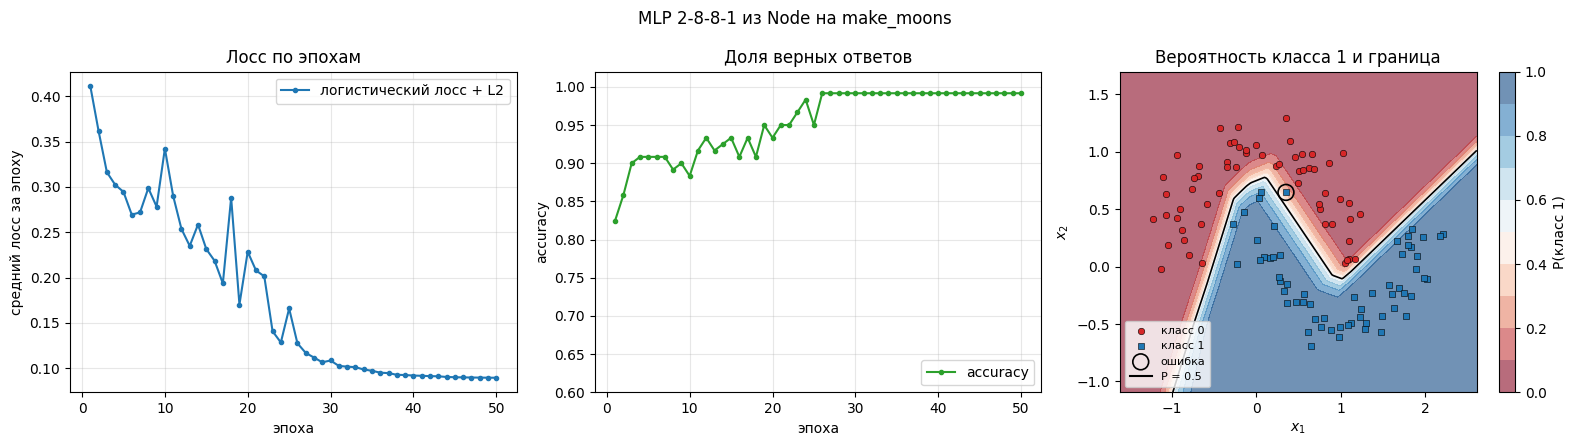

In [12]:
def plot_node_mlp_results(net, history, X, y):
    """Лосс и accuracy по эпохам, вероятность класса 1 на плоскости и ошибки сети."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    epochs = np.arange(1, len(history["loss"]) + 1)

    axes[0].plot(epochs, history["loss"], marker=".", label="логистический лосс + L2")
    axes[0].set(title="Лосс по эпохам", xlabel="эпоха", ylabel="средний лосс за эпоху")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["acc"], marker=".", color="tab:green", label="accuracy")
    axes[1].set(title="Доля верных ответов", xlabel="эпоха", ylabel="accuracy", ylim=(0.6, 1.02))
    axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.3)

    (x_min, y_min), (x_max, y_max) = X.min(axis=0) - 0.4, X.max(axis=0) + 0.4
    gx, gy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 200))
    grid_scores = mlp_scores_numpy(net, np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    grid_prob = 0.5 * (1 + np.tanh(grid_scores / 2))  # sigmoid, но без переполнения exp
    filled = axes[2].contourf(gx, gy, grid_prob, levels=np.linspace(0, 1, 11), cmap="RdBu",
                              alpha=0.6)
    fig.colorbar(filled, ax=axes[2], label="P(класс 1)")
    axes[2].contour(gx, gy, grid_prob, levels=[0.5], colors="k", linewidths=1.2)
    for cls, color, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        axes[2].scatter(X[y == cls, 0], X[y == cls, 1], c=color, marker=marker, s=22,
                        edgecolor="k", linewidth=0.4, label=f"класс {cls}")
    wrong = (mlp_scores_numpy(net, X) > 0) != (y == 1)
    axes[2].scatter(X[wrong, 0], X[wrong, 1], s=130, facecolors="none", edgecolors="k",
                    linewidth=1.2, label="ошибка")
    axes[2].plot([], [], color="k", label="P = 0.5")
    axes[2].set(title="Вероятность класса 1 и граница", xlabel="$x_1$", ylabel="$x_2$")
    axes[2].legend(loc="lower left", fontsize=8)

    fig.suptitle("MLP 2-8-8-1 из Node на make_moons")
    fig.tight_layout()
    plt.show()


plot_node_mlp_results(moons_net, moons_history, moons_X, moons_y)

### Выводы по бонусу

- Градиенты всей сети на полном датасете совпали с torch.autograd: лосс совпадает до 10 знаков (0.4554357579), а максимальная разница градиентов по всем 105 параметрам 4.16e-17, т.е. на уровне ошибок округления float64. Так как обход графа идет по `_args`, это число от запуска к запуску не меняется.
- Обычный SGD на `Node` нормально обучает сеть: средний лосс за эпоху падает с 0.41 на первой эпохе до 0.090 на последней. Пока шаг большой (первые ~20 эпох), лосс заметно скачет, например на 10-й эпохе 0.34 после 0.29 на 5-й, а когда шаг уменьшается, кривая выходит на плато. Accuracy за эпоху растет с 0.825 до 0.992 к 26-й эпохе и дальше не меняется.
- После обучения сеть ошибается на одной точке из 120 (accuracy 0.992, loss 0.0896), прямой проход в numpy по тем же весам дает то же самое. Эта точка класса 1 из-за шума залезла к классу 0 и лежит прямо у границы, на ее "красной" стороне, так что ошибка вполне объяснимая.
- Граница ломаная (сеть с ReLU задает кусочно-линейную функцию), но повторяет форму полумесяцев. Неуверенная зона (вероятность между 0.1 и 0.9) - узкая полоса вдоль границы, а дальше от нее сеть уверена в ответе.
- Обучение заняло порядка 10-20 секунд (точное время в выводе выше), и это для 120 точек и 105 параметров. torch сделал бы то же самое за доли секунды: у нас каждая операция над числом - отдельный объект Python со своим замыканием. Так что скалярный autograd хорош для понимания, а на практике нужны операции сразу над тензорами.

## Выводы

- Класс `Node` реализует все обязательные операции (`+`, `*`, `relu`, `backward`), а также вычитание, деление, унарный минус, степень, `exp`, `log`, `tanh` и `sigmoid`, у каждой своя локальная производная; числа Python можно ставить с любой стороны. Внутри класса только арифметика Python и `math`, без torch.
- `backward()` обходит граф в обратном топологическом порядке, который строится DFS без рекурсии, поэтому цепочка из 10000 операций (глубже лимита рекурсии Python) считается без ошибок. Градиенты накапливаются через `+=`, так что `a * a`, `a + a` и общие подвыражения обрабатываются правильно. Порядок обхода фиксированный (по `_args`), поэтому результаты повторяются при перезапуске до последнего знака.
- Все 28 тестов проходят: значения и градиенты совпадают с torch.autograd на 100 случайных точках для 5 выражений (допуск 1e-9, а в примере выше разница не больше ~1e-16) и с конечными разностями.
- В примере из условия верный ответ - нулевые градиенты у `a, b, c, d`, потому что в точке d = -28 ReLU не пропускает градиент; torch дает то же самое, а вывод в условии противоречит сам себе. При `c = -10` ReLU активен и получаются ожидаемые `a.grad = 1`, `b.grad = -10`, `c.grad = -3`.
- Из `Node` можно собрать и обучить настоящую сеть: MLP 2-8-8-1 с логистическим лоссом на make_moons за 50 эпох SGD ошибается только на одной из 120 обучающих точек.

## Источники

- Andrej Karpathy, The spelled-out intro to neural networks and backpropagation: building micrograd - https://www.youtube.com/watch?v=VMj-3S1tku0
- micrograd - https://github.com/karpathy/micrograd (идея хранить замыкание `_backward` в узле - отсюда)
- CS231n, Backpropagation, Intuitions - https://cs231n.github.io/optimization-2/
- PyTorch, Autograd mechanics (накопление градиентов, `retain_graph`) - https://pytorch.org/docs/stable/notes/autograd.html